# Laboratorio #4 – Análisis exploratorio de datos (EDA)

**Universidad Técnica Nacional**  
**Minería de datos – ISW-911**  
**Asignación grupal (investigación)**

**Integrantes:**
- Karol Miranda Mora
- Katherine Solis Ramirez
- Dylan Jimenez Alfaro
- Josué Alvarez Villalobos

---

**Conjunto de datos:** Duración de expedientes terminados del Observatorio Judicial de Costa Rica (2026).  
**Fuente:** Portal de Datos Abiertos del Poder Judicial de Costa Rica  
https://datosabiertospj.poder-judicial.go.cr/dataset/duracion-de-expedientes-terminados-del-observatorio-judicial-de-costa-rica

**Cómo está organizado el trabajo:**

| Sección | Responsable |
|---|---|
| 1. Exploración inicial | Karol |
| 2. Limpieza de datos | Katherine |
| 3. Transformación | Dylan |
| 4. Análisis y resultados | Josué |


## 1. Exploración inicial (Karol)

### 1.1 Librerías

In [ ]:
%pip install pandas numpy matplotlib seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

### 1.2 Lectura del conjunto de datos desde Git

El archivo se subió al repositorio de GitHub (público) en formato `.csv.gz`, que es un CSV comprimido. El archivo original en Excel pesa 31 MB y el CSV sin comprimir unos 91 MB, así que se prefirió comprimirlo (queda en unos 6 MB) para que el notebook cargue rápido.

Pandas lee el `.csv.gz` directamente desde la URL. Las columnas de códigos se leen como texto para no perder los ceros a la izquierda (por ejemplo `0215`).

In [ ]:
URL = "https://raw.githubusercontent.com/Kyaroruki/Laboratorio-4-Mineria-Datos/main/datos/duracion_terminados.csv.gz"
RUTA_LOCAL = "datos/duracion_terminados.csv.gz"   # respaldo si no hay internet

# Los códigos se leen como texto para conservar los ceros a la izquierda
tipos = {"CodClaseAsu": "str", "CodProcedimiento": "str", "CodFase": "str"}

try:
    df = pd.read_csv(URL, compression="gzip", dtype=tipos)
    print("Datos leídos desde GitHub")
except Exception as e:
    print(f"No se pudo leer desde GitHub ({type(e).__name__}). Se usa el archivo local.")
    df = pd.read_csv(RUTA_LOCAL, compression="gzip", dtype=tipos)

print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")

Datos leídos desde GitHub
Filas: 309,635 | Columnas: 23


### 1.3 Funciones básicas para ver las características del conjunto de datos

In [ ]:
# Primeras filas
df.head()

In [ ]:
# Últimas filas
df.tail()

In [ ]:
# Cantidad de filas y columnas
print("Forma del dataset (filas, columnas):", df.shape)

In [ ]:
# Tipos de dato, cantidad de valores no nulos y memoria usada
df.info()

In [ ]:
# Estadísticas de las columnas numéricas
df.describe()

In [ ]:
# Resumen de las columnas de texto
df.describe(include=["object", "string"]).T

In [ ]:
# Cantidad de valores distintos por columna
df.nunique().sort_values(ascending=False)

In [ ]:
# Una muestra al azar
df.sample(5, random_state=42)

,CodCircuito,DescCircuito,DescMateria,DescTipoDespacho,CodDespacho,DescDespacho,Año,Numero_Mes,CodClaseAsu,DescClaseAsu,CodProcedimiento,Procedimiento,DescEstadoAsunto,AgrEstadoAsunto,CodFase,Fase,TermiMedAlterna,TermiConciliacion,Cant,DurDias,Completitud,Desc_Delito,Ref_Civil
184325,5,CIRCUITO JUDICIAL DE HEREDIA,LABORAL,TRIBUNAL DE TRABAJO,809,TRIBUNAL DE APELACIÓN CIVIL Y TRABAJO DE HERED...,2026,5,JT001,ORDINARIO DE DESPIDO-PRIVADO,NaN,DE CESANTÍA U OTROS EXTREMOS,SENTENCIA,NaN,NaN,4. EN EJECUCION,NaN,No,1,115.00,COMPLETA,NO DELITOS,NaN
178220,47,I CIRCUITO JUDICIAL DE LIMÓN (BATÁN-MATINA),PENAL,FISCALÍA,1521,FISCALÍA DE BATÁN (PENAL),2026,3,0216,DENUNCIA POR ESCRITO,NaN,ORDINARIO,"SOL. DESESTIMACIÓN, ART. 299 (ELEMENTOS PROBAT...",NaN,NaN,Etapa Intermedia,No,NaN,1,169.00,COMPLETA,DIFUSIÓN DE PORNOGRAFÍA,NaN
294564,5,CIRCUITO JUDICIAL DE HEREDIA,PENAL JUVENIL,FISCALÍA PENAL JUVENIL,811,FISCALÍA ADJUNTA DE HEREDIA (PENAL JUVENIL),2026,2,0215,DENUNCIA EN DESPACHO,NaN,ESPECIAL,SOB.DEF. PRESCRIP.ART.31 C.P.P.,Sobreseimiento definitivo,NaN,Fase Conclusiva de la Investigación,No,NaN,1,242.00,COMPLETA,DESÓRDENES,NaN
162213,42,CIRCUITO JUDICIAL DE PUNTARENAS (GARABITO),TRÁNSITO,JUZGADO DE TRÁNSITO,1598,JUZGADO CONTRAVENCIONAL DE GARABITO (TRÁNSITO),2026,4,0540,COLISIÓN ENTRE VEHÍCULOS-ACCIDENTE SIMPLE,NaN,COLISIÓN,INCOMPETENCIA,Incompentencia,NaN,1. Inicial,NaN,No,7,211.00,COMPLETA,DESCONOCIDO,NaN
79087,11,Circuito Judicial de Heredia,VIOLENCIA DOMÉSTICA,Juzgado,1612,"JUZGADO DE PENSIONES, CONTRA LA VIOLENCIA DOMÉ...",2026,8,1111,VIOLENCIA DOMÉSTICA,NaN,VIOLENCIA DOMÉSTICA ORDINARIO VERBAL (MUJERES ...,INCOMPETENCIA,Incompentencia,NaN,NaN,NaN,No,1,1.00,COMPLETA,DESCONOCIDO,NaN


**Primeras observaciones**
- El dataset tiene 309 635 filas y 23 columnas, cada fila es un grupo de expedientes terminados con su duración en días.
- Hay columnas numéricas (`DurDias`, `Cant`, `Numero_Mes`, `Año`, `CodCircuito`, `CodDespacho`) y muchas de texto.
- `Año` tiene un solo valor (2026), así que no aporta información.
- `CodProcedimiento` y `CodFase` vienen totalmente vacías.
- `DurDias` tiene valores muy altos frente a su mediana, esto se analiza en la sección de valores atípicos.

### 1.4 Cambio de nombres de las columnas a español

Los nombres originales ya estaban en español pero abreviados (`Cant`, `DurDias`, `TermiMedAlterna`) y mezclaban mayúsculas, guiones bajos y una `ñ` (`Año`). Se pasaron a nombres completos en minúscula y con guion bajo, para que sean fáciles de leer y de escribir en el código. La `ñ` de `Año` se cambió a `anio` para evitar problemas de codificación.

In [ ]:
nombres_es = {
    "CodCircuito": "codigo_circuito",
    "DescCircuito": "circuito",
    "DescMateria": "materia",
    "DescTipoDespacho": "tipo_despacho",
    "CodDespacho": "codigo_despacho",
    "DescDespacho": "despacho",
    "Año": "anio",
    "Numero_Mes": "mes",
    "CodClaseAsu": "codigo_clase_asunto",
    "DescClaseAsu": "clase_asunto",
    "CodProcedimiento": "codigo_procedimiento",
    "Procedimiento": "procedimiento",
    "DescEstadoAsunto": "estado_asunto",
    "AgrEstadoAsunto": "estado_asunto_agrupado",
    "CodFase": "codigo_fase",
    "Fase": "fase",
    "TermiMedAlterna": "termina_medida_alterna",
    "TermiConciliacion": "termina_conciliacion",
    "Cant": "cantidad",
    "DurDias": "duracion_dias",
    "Completitud": "completitud",
    "Desc_Delito": "delito",
    "Ref_Civil": "referencia_civil",
}

df = df.rename(columns=nombres_es)
print(df.columns.tolist())

['codigo_circuito', 'circuito', 'materia', 'tipo_despacho', 'codigo_despacho', 'despacho', 'anio', 'mes', 'codigo_clase_asunto', 'clase_asunto', 'codigo_procedimiento', 'procedimiento', 'estado_asunto', 'estado_asunto_agrupado', 'codigo_fase', 'fase', 'termina_medida_alterna', 'termina_conciliacion', 'cantidad', 'duracion_dias', 'completitud', 'delito', 'referencia_civil']


In [ ]:
df.head()

---
## 2. Limpieza de datos (Katherine)

Trabaja con el DataFrame `df` ya con los nombres en español (por ejemplo `duracion_dias`, `cantidad`, `fase`).

- [ ] Identificar valores nulos
- [ ] Gráficos de valores nulos
- [ ] Identificar valores atípicos
- [ ] Gráficos de valores atípicos
- [ ] Funciones para imputar o tratar nulos y atípicos, con la justificación de cada decisión en la documentación




                         nulos  porcentaje
codigo_procedimiento    309635      100.00
codigo_fase             309635      100.00
referencia_civil        293419       94.76
estado_asunto_agrupado  224419       72.48
termina_conciliacion    186720       60.30
termina_medida_alterna  122915       39.70
fase                     32748       10.58
clase_asunto               597        0.19
duracion_dias              273        0.09
codigo_clase_asunto         54        0.02
codigo_despacho              0        0.00
materia                      0        0.00
circuito                     0        0.00
codigo_circuito              0        0.00
tipo_despacho                0        0.00
anio                         0        0.00
despacho                     0        0.00
mes                          0        0.00
estado_asunto                0        0.00
procedimiento                0        0.00
cantidad                     0        0.00
completitud                  0        0.00
delito     

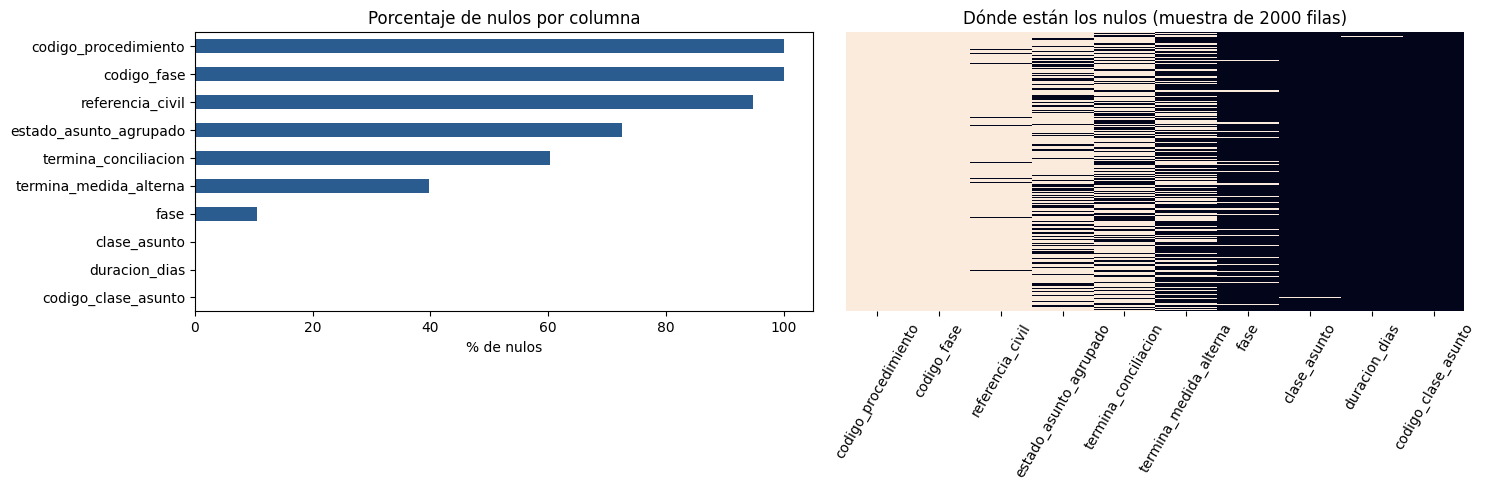

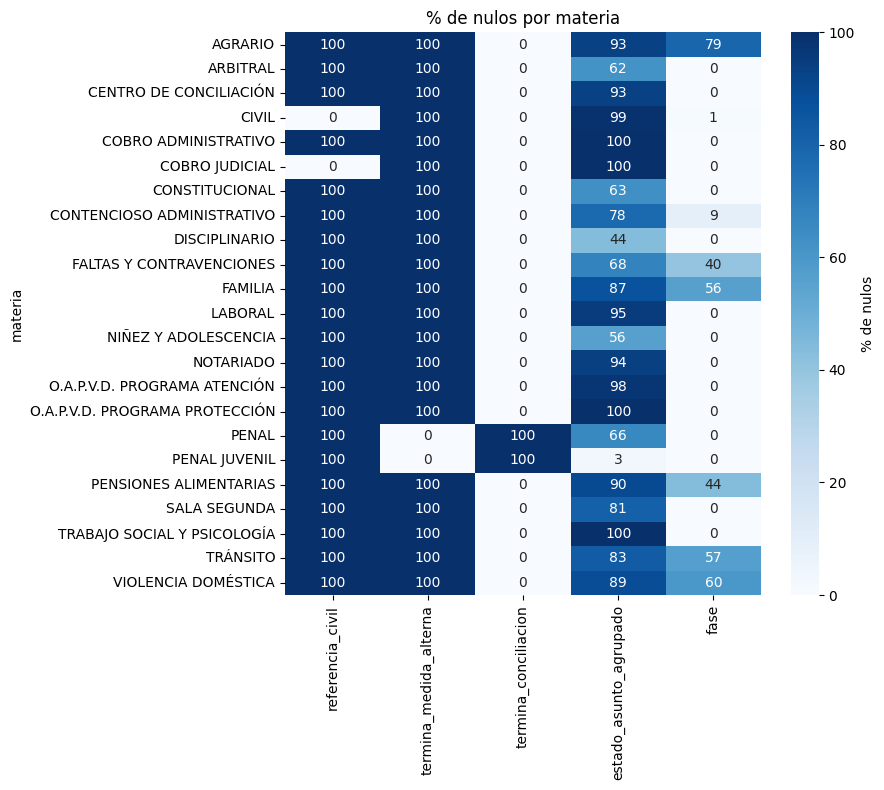

In [ ]:
# 2.1 VALORES NULOS (reales y disfrazados de texto)
VALORES_TIPO_NULO = ["", "NA", "N/A", "NULL", "NONE", "NAN", "-",
                     "SIN DATO", "NO APLICA", "DESCONOCIDO", "IGNORADO"]

def resumen_nulos(datos):
    """Cantidad y porcentaje de nulos de cada columna."""
    tabla = pd.DataFrame({"nulos": datos.isna().sum(),
                          "porcentaje": (datos.isna().mean() * 100).round(2)})
    return tabla.sort_values("nulos", ascending=False)

def buscar_nulos_disfrazados(datos):
    """Busca textos que funcionan como nulo (ej. 'DESCONOCIDO') en columnas de texto."""
    filas = []
    for col in datos.select_dtypes(exclude="number").columns:
        texto = datos[col].astype("string").str.strip().str.upper()
        for valor in VALORES_TIPO_NULO:
            n = int((texto == valor).sum())
            if n > 0:
                filas.append([col, valor, n, round(n / len(datos) * 100, 2)])
    return (pd.DataFrame(filas, columns=["columna", "valor", "cantidad", "porcentaje"])
              .sort_values("cantidad", ascending=False).reset_index(drop=True))

def graficar_nulos(datos):
    """Barras con el % de nulos y mapa de calor de dónde están."""
    tabla = resumen_nulos(datos)
    tabla = tabla[tabla["nulos"] > 0]
    if tabla.empty:
        print("No hay valores nulos.")
        return
    fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
    tabla["porcentaje"].sort_values().plot(kind="barh", ax=ejes[0], color="#2b5c8f")
    ejes[0].set_title("Porcentaje de nulos por columna")
    ejes[0].set_xlabel("% de nulos")
    muestra = datos[tabla.index].sample(2000, random_state=1)  # muestra para que no sea pesado
    sns.heatmap(muestra.isna(), cbar=False, yticklabels=False, ax=ejes[1])
    ejes[1].set_title("Dónde están los nulos (muestra de 2000 filas)")
    ejes[1].tick_params(axis="x", rotation=60)
    plt.tight_layout()
    plt.show()

def nulos_por_grupo(datos, columnas, grupo):
    """% de nulos de cada columna dentro de cada grupo (para ver si dependen de la materia)."""
    return datos.groupby(grupo)[columnas].apply(lambda g: (g.isna().mean() * 100).round(0))

def graficar_nulos_por_grupo(datos, columnas, grupo):
    """Mapa de calor del % de nulos por grupo: muestra si los nulos son estructurales."""
    tabla = nulos_por_grupo(datos, columnas, grupo)
    plt.figure(figsize=(9, 8))
    sns.heatmap(tabla, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% de nulos"})
    plt.title(f"% de nulos por {grupo}")
    plt.tight_layout()
    plt.show()

print(resumen_nulos(df))
print(buscar_nulos_disfrazados(df))
print("Registros duplicados:", df.duplicated().sum())
graficar_nulos(df)
graficar_nulos_por_grupo(df, ["referencia_civil", "termina_medida_alterna", "termina_conciliacion",
                              "estado_asunto_agrupado", "fase"], "materia")

**Hallazgos de valores nulos**

El conjunto tiene 309 635 filas y 23 columnas originales, sin registros duplicados.

- `codigo_procedimiento` y `codigo_fase` están 100 % vacías. Les siguen `referencia_civil` (94.8 %), `estado_asunto_agrupado` (72.5 %), `termina_conciliacion` (60.3 %), `termina_medida_alterna` (39.7 %) y `fase` (10.6 %). `clase_asunto` (597), `duracion_dias` (273) y `codigo_clase_asunto` (54) tienen muy pocos.
- El mapa de calor por materia muestra que la mayoría de esos nulos son estructurales: la columna solo aplica a ciertas materias (por ejemplo, `termina_medida_alterna` solo tiene datos en PENAL y PENAL JUVENIL, y `referencia_civil` solo en CIVIL y COBRO JUDICIAL).
- Hay nulos disfrazados de texto: `delito` tiene "DESCONOCIDO" (25.6 %), "IGNORADO" (2.8 %) y "NO APLICA" (1.4 %); `procedimiento` tiene "DESCONOCIDO" (1.4 %) y "-" (0.2 %).
- Evidencia: gráfico de barras, mapa de calor de la muestra y mapa de calor por materia.

             columna  inferiores  superiores  total  porcentaje
0      duracion_dias           0        1541   1541        0.50
1           cantidad           0       27769  27769        8.97
2  duracion_promedio           0           1      1        0.00
             columna  inferiores  superiores  total  porcentaje
0      duracion_dias        1878         304   2182        0.70
1           cantidad           0       25733  25733        8.31
2  duracion_promedio        2167         123   2290        0.74


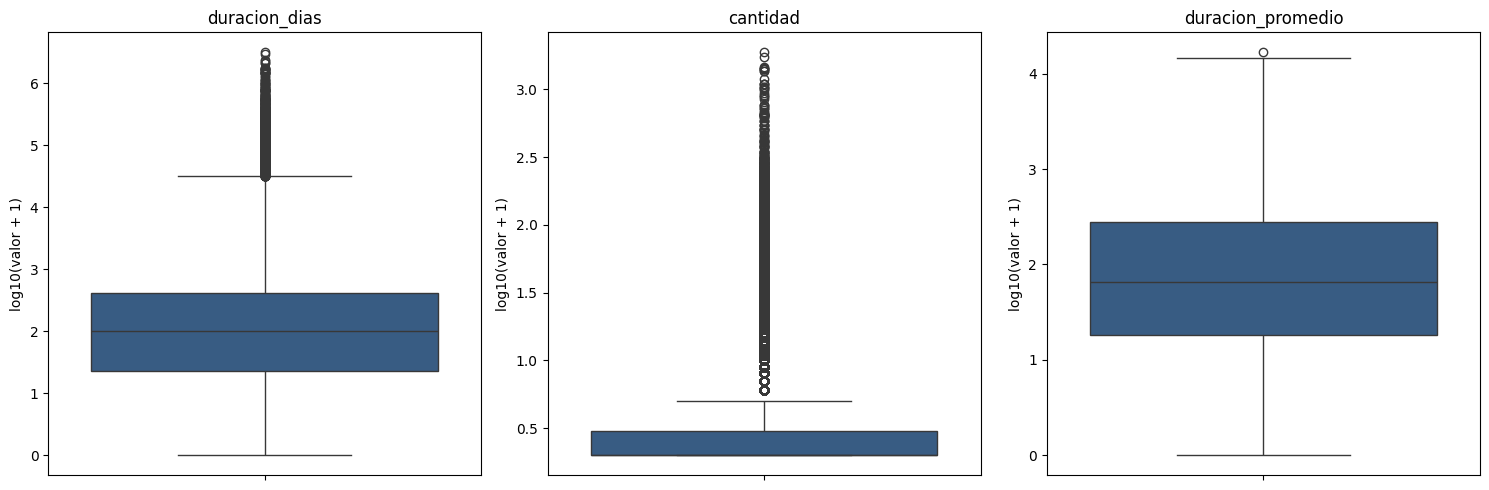

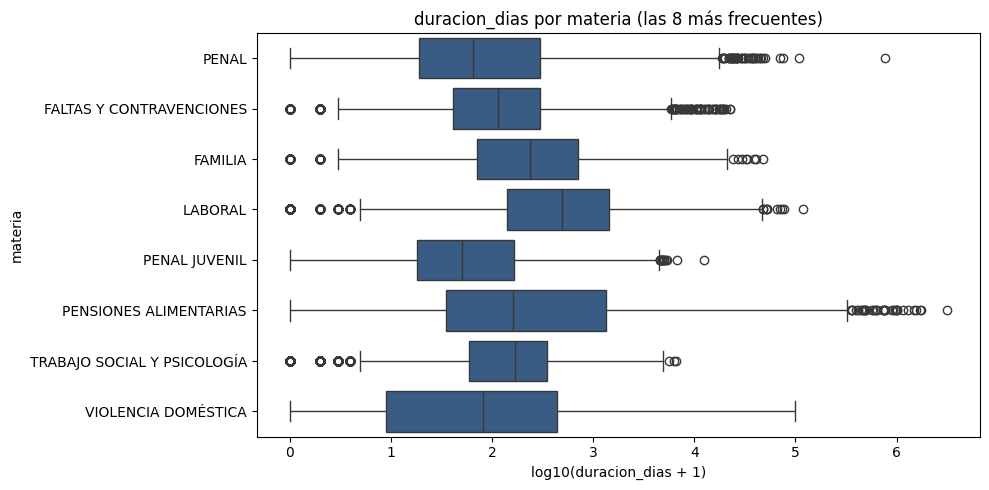

In [ ]:
# 2.2 VALORES ATÍPICOS
# duracion_dias es una suma de días de varios expedientes; se crea el promedio por expediente
df["duracion_promedio"] = df["duracion_dias"] / df["cantidad"]

def limites_iqr(serie, usar_log=False):
    """
    Límites inferior y superior con la regla 1.5 x IQR.
    Con usar_log=True se calculan sobre log10(x + 1), porque las duraciones
    tienen una cola muy larga (igual que se hizo con log_total en el taller de R).
    """
    valores = serie.dropna()
    if usar_log:
        valores = np.log10(valores + 1)
    q1, q3 = valores.quantile(0.25), valores.quantile(0.75)
    iqr = q3 - q1
    inf, sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    if usar_log:
        inf, sup = 10 ** inf - 1, 10 ** sup - 1
    return max(inf, 0), sup   # una duración no puede ser negativa

def marcar_atipicos(datos, columna, usar_log=False, grupo=None, tipo="ambos", min_grupo=30):
    """
    True en cada registro atípico (tipo: 'inferior', 'superior' o 'ambos').
    Con grupo, cada categoría usa sus propios límites; los grupos con menos de min_grupo
    registros usan el límite general, porque con tan pocos datos el IQR no es confiable.
    """
    limite_general = limites_iqr(datos[columna], usar_log)
    def marcar(s):
        inf, sup = limites_iqr(s, usar_log) if s.notna().sum() >= min_grupo else limite_general
        if tipo == "inferior":
            return s < inf
        if tipo == "superior":
            return s > sup
        return (s < inf) | (s > sup)
    if grupo is None:
        return marcar(datos[columna])
    return datos.groupby(grupo)[columna].transform(marcar).astype(bool)

def resumen_atipicos(datos, columnas, usar_log=False, grupo=None):
    """Cantidad de atípicos inferiores y superiores de cada columna."""
    filas = []
    for col in columnas:
        bajos = int(marcar_atipicos(datos, col, usar_log, grupo, "inferior").sum())
        altos = int(marcar_atipicos(datos, col, usar_log, grupo, "superior").sum())
        filas.append([col, bajos, altos, bajos + altos, round((bajos + altos) / len(datos) * 100, 2)])
    return pd.DataFrame(filas, columns=["columna", "inferiores", "superiores", "total", "porcentaje"])

def graficar_atipicos(datos, columnas, grupo=None, top=8):
    """Diagrama de caja de cada medida y, si hay grupo, por categoría (las más frecuentes)."""
    fig, ejes = plt.subplots(1, len(columnas), figsize=(5 * len(columnas), 5))
    for ax, col in zip(np.atleast_1d(ejes), columnas):
        sns.boxplot(y=np.log10(datos[col] + 1), ax=ax, color="#2b5c8f")
        ax.set_title(col)
        ax.set_ylabel("log10(valor + 1)")
    plt.tight_layout()
    plt.show()
    if grupo is not None:
        principales = datos[grupo].value_counts().head(top).index
        sub = datos[datos[grupo].isin(principales)]
        plt.figure(figsize=(10, 5))
        sns.boxplot(data=sub, y=grupo, x=np.log10(sub[columnas[0]] + 1), color="#2b5c8f")
        plt.xlabel(f"log10({columnas[0]} + 1)")
        plt.title(f"{columnas[0]} por {grupo} (las {top} más frecuentes)")
        plt.tight_layout()
        plt.show()

columnas_medidas = ["duracion_dias", "cantidad", "duracion_promedio"]
print(resumen_atipicos(df, columnas_medidas, usar_log=True))                    # un límite general
print(resumen_atipicos(df, columnas_medidas, usar_log=True, grupo="materia"))   # un límite por materia
graficar_atipicos(df, columnas_medidas, grupo="materia")

## Hallazgos de valores atípicos

- Se analizaron `duracion_dias`, `cantidad` y `duracion_promedio` (los códigos y el mes no son medidas). Se usó la regla 1.5 × IQR sobre el logaritmo (la cola es muy larga) y un límite por materia (las duraciones varían mucho entre materias).
- Con un límite general casi no se detectan atípicos en `duracion_promedio` (1 registro). Por materia son 2 290: 2 167 inferiores y 123 superiores.
- Los inferiores son duraciones muy cortas (cerca de 980 son de 0 días), que son válidas: un asunto puede cerrarse el mismo día. Los superiores sí son expedientes de duración extrema.
- `cantidad` tiene 25 733 atípicos superiores (8.3 %); son grupos grandes reales.
- Evidencia: diagramas de caja generales y por materia.

In [ ]:
# 2.3 FUNCIONES DE IMPUTACIÓN Y TRATAMIENTO

def eliminar_columnas_vacias(datos):
    """
    Elimina las columnas que están 100% vacías.
    Justificación: no tienen ningún dato que analizar ni imputar.
    """
    vacias = [c for c in datos.columns if datos[c].isna().all()]
    print("Columnas vacías eliminadas:", vacias)
    return datos.drop(columns=vacias)

def unificar_desconocidos(datos, columnas, equivalentes=("-", "IGNORADO", "SIN DATO")):
    """
    Une en 'DESCONOCIDO' los textos que funcionan como nulo y significan lo mismo
    ('-', 'IGNORADO', 'SIN DATO').
    Justificación: se conservan como categoría (no se borran ni se rellenan con la moda)
    porque son una respuesta real del sistema. 'NO APLICA' se deja aparte: significa otra cosa.
    """
    datos = datos.copy()
    for col in columnas:
        texto = datos[col].astype("string").str.strip().str.upper()
        datos.loc[texto.isin(equivalentes), col] = "DESCONOCIDO"
    return datos

def recuperar_clase_por_codigo(datos):
    """
    Recupera la descripción de la clase de asunto a partir de su código (la más frecuente).
    Justificación: es una recuperación exacta desde datos del mismo archivo, no una estimación.
    """
    datos = datos.copy()
    mapa = (datos.dropna(subset=["clase_asunto"]).groupby("codigo_clase_asunto")["clase_asunto"]
            .agg(lambda s: s.mode().iloc[0]))
    faltan = datos["clase_asunto"].isna() & datos["codigo_clase_asunto"].notna()
    datos.loc[faltan, "clase_asunto"] = datos.loc[faltan, "codigo_clase_asunto"].map(mapa)
    print("Descripciones recuperadas desde el código:", int((faltan & datos["clase_asunto"].notna()).sum()))
    return datos

def imputar_categoricas(datos, reglas):
    """
    Rellena nulos de texto con una etiqueta por columna (diccionario columna -> texto).
    Justificación: la mayoría de los nulos son ESTRUCTURALES (la columna no aplica a esa
    materia), así que la moda inventaría datos; una etiqueta propia los conserva y los distingue.
    """
    datos = datos.copy()
    for col, texto in reglas.items():
        if col in datos.columns:
            datos[col] = datos[col].fillna(texto)
    return datos

def imputar_duracion(datos):
    """
    Rellena los nulos de duracion_dias así: mediana de la duración PROMEDIO de su materia
    y su completitud, multiplicada por la cantidad de expedientes de la fila.
    Justificación: duracion_dias es una suma, por eso se estima el promedio y se multiplica;
    la completitud se usa porque separa duraciones muy distintas (mediana de 60 vs 2 195 días).
    Se marca con 'duracion_imputada' qué filas se rellenaron.
    """
    datos = datos.copy()
    promedio = datos["duracion_dias"] / datos["cantidad"]
    mediana_fina = promedio.groupby([datos["materia"], datos["completitud"]]).transform("median")
    mediana_materia = promedio.groupby(datos["materia"]).transform("median")
    estimado = promedio.fillna(mediana_fina).fillna(mediana_materia).fillna(promedio.median())
    datos["duracion_imputada"] = datos["duracion_dias"].isna()
    datos["duracion_dias"] = datos["duracion_dias"].fillna(estimado * datos["cantidad"])
    print("Duraciones imputadas:", int(datos["duracion_imputada"].sum()))
    return datos

def topar_atipicos(datos, columna, columna_nueva, usar_log=False, grupo=None,
                   tipo="superior", min_grupo=30):
    """
    Recorta los atípicos al límite 1.5 x IQR de su grupo en una columna nueva.
    Por defecto solo el lado SUPERIOR: una duración corta (incluso 0 días) es válida, mientras
    que las muy largas son las que distorsionan. Se conservan todos los registros.
    """
    datos = datos.copy()
    limite_general = limites_iqr(datos[columna], usar_log)
    def topar(s):
        inf, sup = limites_iqr(s, usar_log) if s.notna().sum() >= min_grupo else limite_general
        return s.clip(lower=inf if tipo != "superior" else None,
                      upper=sup if tipo != "inferior" else None)
    if grupo is None:
        datos[columna_nueva] = topar(datos[columna])
    else:
        datos[columna_nueva] = datos.groupby(grupo)[columna].transform(topar)
    print(f"Valores recortados en {columna_nueva}:", int((datos[columna_nueva] != datos[columna]).sum()))
    return datos

REGLAS_CATEGORICAS = {
    "referencia_civil": "NO APLICA",
    "termina_medida_alterna": "NO APLICA",
    "termina_conciliacion": "NO APLICA",
    "estado_asunto_agrupado": "SIN AGRUPAR",
    "fase": "SIN FASE",
    "codigo_clase_asunto": "DESCONOCIDO",
    "clase_asunto": "DESCONOCIDO",
}

df_limpio = eliminar_columnas_vacias(df.drop(columns=["duracion_promedio"]))
df_limpio = unificar_desconocidos(df_limpio, ["delito", "procedimiento"])
df_limpio = recuperar_clase_por_codigo(df_limpio)
df_limpio = imputar_categoricas(df_limpio, REGLAS_CATEGORICAS)
df_limpio = imputar_duracion(df_limpio)
df_limpio["duracion_promedio"] = df_limpio["duracion_dias"] / df_limpio["cantidad"]
df_limpio = topar_atipicos(df_limpio, "duracion_promedio", "duracion_promedio_ajustada",
                           usar_log=True, grupo="materia")
# cantidad y duracion_dias NO se recortan (ver documentación)

print("Nulos totales:", int(df_limpio.isna().sum().sum()), "| Forma:", df_limpio.shape)

Columnas vacías eliminadas: ['codigo_procedimiento', 'codigo_fase']
Descripciones recuperadas desde el código: 502
Duraciones imputadas: 273
Valores recortados en duracion_promedio_ajustada: 124
Nulos totales: 0 | Forma: (309635, 24)


## Decisiones de limpieza e imputación
1. **Columnas vacías.** Se eliminaron `codigo_procedimiento` y `codigo_fase` (100 % vacías): no hay datos que analizar.

2. **Nulos estructurales: etiqueta, no moda.** Según el mapa de calor, la mayoría de los nulos ocurren porque la columna no aplica a la materia. `termina_medida_alterna`, `termina_conciliacion` y `referencia_civil` se rellenaron con "NO APLICA" (en `referencia_civil`, "NO" habría sido falso). `estado_asunto_agrupado` se rellenó con "SIN AGRUPAR" y `fase` con "SIN FASE". Se evitó la moda porque inventaría información.

3. **Nulos disfrazados.** "IGNORADO" y "-" se unieron con "DESCONOCIDO" en `delito` y `procedimiento`. Se conservan como categoría porque son una respuesta real del sistema (`delito` queda con 28.5 % en "DESCONOCIDO"). "NO APLICA" se dejó aparte porque significa otra cosa.

4. **`clase_asunto`.** De 597 nulos, 502 se recuperaron con su `codigo_clase_asunto` (la descripción más frecuente de ese código). Es una recuperación exacta desde el mismo archivo. Los 95 restantes quedaron como "DESCONOCIDO".

5. **Por qué se creó `duracion_promedio`.** No hay diccionario de datos que explique `duracion_dias`. Al compararla con `cantidad`, su mediana crece casi proporcional (65 días con 1 expediente, 127 con 2, 220 con 3 a 5, 437 con 6 a 10, 1 222 con 11 a 50), mientras que la duración por expediente se mantiene entre 60 y 68. Se concluye que es una suma. Es una interpretación basada en los datos, no confirmada oficialmente.

6. **Nulos de `duracion_dias` (273 filas, 0.09 %).** No son aleatorios: afectan al 0.53 % de los casos INCOMPLETA y al 0.07 % de los COMPLETA. Se rellenaron con la mediana de la duración promedio de su materia y su completitud, multiplicada por su `cantidad`. Se usó la completitud porque separa duraciones muy distintas (mediana de 60 días en COMPLETA y de 2 195 en INCOMPLETA). La columna `duracion_imputada` marca esas filas.

7. **Atípicos: solo se recortó el lado superior.** Los inferiores son duraciones cortas válidas, así que no se tocaron. Los 124 valores superiores de `duracion_promedio` se recortaron al límite de su materia en la columna nueva `duracion_promedio_ajustada`: así se conservan todos los registros y la columna original no cambia. Las materias con menos de 30 registros usan el límite general, porque con tan pocos datos el IQR no es confiable.

8. **Lo que no se recortó.** `cantidad`, porque los grupos grandes son reales y recortarla cambiaría el 8.3 % de los datos. `duracion_dias`, porque sus valores altos se explican por la cantidad de expedientes (los atípicos superiores de la suma tienen una `cantidad` mediana de 116, contra 1 en el resto), no por errores.

9. **Limitaciones.** Las medianas y límites se calcularon con todo el conjunto; en un modelo real deberían calcularse solo con los datos de entrenamiento. La columna `completitud` está muy ligada a la duración: INCOMPLETA es el 3 % de las filas, pero concentra las duraciones más extremas.

---
## 3. Transformación (Dylan)

Pendiente:
- [ ] Corregir tipos de datos
- [ ] Convertir variables categóricas a numéricas
- [ ] Normalización o estandarización

---
## 4. Análisis y resultados (Josué)

Pendiente:
- [ ] Correlaciones y gráficos
- [ ] Variable dependiente
- [ ] Modelo propuesto (clasificación o regresión) y justificación
- [ ] Guardar el dataset final como `data_process.csv`